# 04 — Competição temporal de modelos e ensembles

Este notebook compara candidatos de regressão para prever o consumo diário no horizonte de sete dias. Usa as mesmas origens de sexta-feira e os mesmos alvos observados do Notebook 03. Em cada origem, o ajuste usa apenas exemplos com alvo anterior à origem; as variáveis de calendário e cardápio são conhecidas para o dia futuro, enquanto o histórico de consumo é limitado ao corte temporal.

O inventário reúne 17 estimadores dos experimentos anteriores, uma árvore de decisão e dois candidatos exploratórios de séries temporais (Prophet e SARIMAX). A inclusão de um candidato não implica que seja adequado ou vencedor: desempenho, cobertura e falhas serão reportados.

## Pré-processamento dentro de cada fold

| Família/candidatos | Valores ausentes | Categorias | Escala numérica |
|---|---|---|---|
| Regressão linear, Ridge, Lasso, ElasticNet, BayesianRidge, Huber | mediana numérica; categoria explícita para ausente | One-Hot, categorias desconhecidas ignoradas | StandardScaler ajustado só no treino |
| KNN, SVR-RBF, MLP | mediana/categoria explícita | One-Hot | StandardScaler ajustado só no treino |
| DecisionTree, RandomForest, ExtraTrees, GradientBoosting, AdaBoost, HistGradientBoosting, XGBoost, LightGBM | mediana numérica; categoria explícita | One-Hot | sem escala; árvores não dependem da escala |
| CatBoost | mediana numérica; token de ausente categórico | categorias nativas do CatBoost | sem escala |
| Prophet | imputação mediana de regressores selecionados dentro do treino | regressores numéricos selecionados | padronização interna automática do Prophet |
| SARIMAX | dias sem observação permanecem ausentes (NaN), nunca são tratados como consumo zero | não aplicável | escala temporal nativa |

Imputação, codificação, remoção de colunas constantes e escalonamento são ajustados de novo em cada treino. O histórico de popularidade de cardápio foi criado em cada origem sem consultar o consumo futuro. Os hiperparâmetros são configurações iniciais controladas, não uma busca exaustiva; assim reduzimos o risco de ajustar o teste repetidamente. Previsões negativas são truncadas em zero porque a quantidade de refeições não pode ser negativa; previsões com magnitude acima de `max(1000, 5 × maior consumo de treino)` são rejeitadas como numericamente implausíveis e registradas como falha do fold.

## Ensembles avaliados

Média simples; média com peso igual por família; média/mediana dos três e cinco melhores candidatos conforme folds OOF anteriores; melhor candidato prequential por origem; média ponderada pelo inverso do MAE OOF anterior com encolhimento para pesos iguais; top 5 ponderado; e stacking temporal com Ridge. Pesos e candidatos de cada origem ficam registrados. Na primeira origem, métodos adaptativos começam com fallback explícito, sem usar rótulos do próprio fold.

Excesso e falta são erros de previsão simulados. Sem quantidade efetivamente produzida e refeições servidas, não são medidas de desperdício ou de falta real.

In [1]:
from pathlib import Path
from datetime import datetime
import shutil
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "consumo_cardapio_calendario"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
SCRIPTS = ROOT / "scripts"
if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))
from feature_engineering_temporal import read_gold, read_calendar, get_predictor_columns
from competir_modelos_temporalmente import model_specs, run_competition, aggregate_metrics

FEATURES_PATH = FEATURES_DIR / "features_supervisionadas_horizonte_7d.csv"
FOLDS_PATH = LINE_RESULTS / "03_baselines_walk_forward" / "folds_walk_forward.csv"
BASELINE_PATH = LINE_RESULTS / "03_baselines_walk_forward" / "previsoes_baselines_pareadas.csv"
OUT = LINE_RESULTS / "04_competicao_modelos_ensembles"
if OUT.exists() and any(OUT.iterdir()):
    backup = ROOT / "backup" / f"resultados_04_{datetime.now():%Y%m%d_%H%M%S}"
    backup.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUT, backup)
    print(f"Resultados anteriores preservados em: {backup}")
OUT.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

features = pd.read_csv(FEATURES_PATH, encoding="utf-8-sig", low_memory=False)
features["data_alvo"] = pd.to_datetime(features["data_alvo"], errors="raise").dt.normalize()
features["origem_previsao"] = pd.to_datetime(features["origem_previsao"], errors="coerce").dt.normalize()
gold = read_gold()
calendar = read_calendar()
folds = pd.read_csv(FOLDS_PATH, encoding="utf-8-sig")
folds["origem"] = pd.to_datetime(folds["origem"], errors="raise").dt.normalize()
baseline_raw = pd.read_csv(BASELINE_PATH, encoding="utf-8-sig")
baseline_raw["data"] = pd.to_datetime(baseline_raw["data"], errors="raise").dt.normalize()

specs = model_specs()
predictors = get_predictor_columns(features)
assert "consumo_total" not in predictors, "O alvo entrou no conjunto de preditores."
assert "consumo_total_csv_recebido" not in predictors, "Campo de auditoria entrou nos preditores."
print(f"Features: {len(features)} exemplos, {len(predictors)} preditores | folds: {len(folds)}")
display(pd.DataFrame([{"modelo": s.name, "familia": s.family, "escalonamento": "sim" if s.scale_numeric else "não (ou nativo)"} for s in specs]))

from cache_auditado import carregar_cache_auditado
REUSO_AUDITADO = carregar_cache_auditado(ROOT, OUT)


Resultados anteriores preservados em: F:\PRODUTO_MESTRADO\backup\resultados_04_20261003_005047
Features: 500 exemplos, 71 preditores | folds: 104


,modelo,familia,escalonamento
0,LinearRegression,linear,sim
1,Ridge,linear,sim
2,Lasso,linear,sim
3,ElasticNet,linear,sim
4,BayesianRidge,linear,sim
5,Huber,linear,sim
6,KNN,distance,sim
7,SVR_RBF,distance,sim
8,MLP,neural,sim
9,DecisionTree,tree,não (ou nativo)


## Verificação rápida de execução

Antes da competição completa, ajustamos uma amostra de modelos representativos em duas origens: modelo linear escalonado, árvore, CatBoost nativo e as duas alternativas temporais. Esse passo verifica imports, formatos e geração de previsões. Não é usado para escolher campeões.

In [2]:
if not REUSO_AUDITADO:
    smoke_models = ["Ridge", "DecisionTree", "CatBoost_native", "Prophet", "SARIMAX"]
    smoke_predictions, smoke_failures, smoke_audit, smoke_weights = run_competition(
        features, gold, calendar, folds.head(2), model_names=smoke_models,
        progress_callback=lambda p: print(f"smoke fold {p['fold_number']}/{p['fold_count']}: {p['models_ok']} modelos OK, {p['models_failed']} falhas")
    )
    print(f"Previsões rápidas: {len(smoke_predictions):,} | falhas registradas: {len(smoke_failures)}")
    if not smoke_failures.empty:
        display(smoke_failures)
    assert not smoke_predictions.empty, 'Verificação rápida não produziu previsões.'
else:
    print("Imports e saídas previamente auditados; reuso solicitado.")


00:50:51 - cmdstanpy - INFO - Chain [1] start processing


00:50:52 - cmdstanpy - INFO - Chain [1] done processing


smoke fold 1/2: 5 modelos OK, 0 falhas


00:50:56 - cmdstanpy - INFO - Chain [1] start processing


00:50:56 - cmdstanpy - INFO - Chain [1] done processing


smoke fold 2/2: 5 modelos OK, 0 falhas
Previsões rápidas: 140 | falhas registradas: 0


## Competição completa

Serão avaliados todos os modelos do inventário em todos os folds. A cada cinco folds, previsões parciais e falhas são salvas para permitir recuperação do progresso.

In [3]:
def save_checkpoint(predictions, failures, audit, weights):
    predictions.to_csv(OUT / f"previsoes_parciais_{RUN_ID}.csv", index=False, encoding="utf-8-sig")
    failures.to_csv(OUT / f"falhas_parciais_{RUN_ID}.csv", index=False, encoding="utf-8-sig")
    audit.to_csv(OUT / f"auditoria_ensembles_parcial_{RUN_ID}.csv", index=False, encoding="utf-8-sig")
    weights.to_csv(OUT / f"pesos_ensembles_parcial_{RUN_ID}.csv", index=False, encoding="utf-8-sig")

def progress(p):
    if p["fold_number"] % 5 == 0 or p["fold_number"] == p["fold_count"]:
        elapsed_min = p["elapsed_seconds"] / 60
        print(f"fold {p['fold_number']}/{p['fold_count']} | origem {p['fold']} | treino {p['n_train']} | "
              f"modelos OK {p['models_ok']} | falhas {p['models_failed']} | {elapsed_min:.1f} min")

if not REUSO_AUDITADO:
    predictions_raw, failures, ensemble_audit, ensemble_weights = run_competition(
        features, gold, calendar, folds,
        progress_callback=progress, checkpoint_callback=save_checkpoint
    )
else:
    predictions_raw = pd.read_csv(OUT / "previsoes_modelos_ensembles_baselines.csv")
    for col in ["data", "origem"]:
        predictions_raw[col] = pd.to_datetime(predictions_raw[col], format="mixed").dt.normalize()
    predictions_raw = predictions_raw.loc[predictions_raw["familia"].ne("baseline")].copy()
    failures = pd.read_csv(OUT / "falhas_modelos.csv")
    ensemble_audit = pd.read_csv(OUT / "auditoria_ensembles.csv")
    ensemble_weights = pd.read_csv(OUT / "pesos_ensembles_por_fold.csv")
print(f"Previsões de modelos e ensembles: {len(predictions_raw):,}")
print(f"Falhas de ajuste/previsão registradas: {len(failures):,}")
if not failures.empty:
    display(failures.groupby(["modelo", "tipo_erro"], dropna=False).size().rename("ocorrencias").reset_index().sort_values("ocorrencias", ascending=False))


F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


00:51:04 - cmdstanpy - INFO - Chain [1] start processing


00:51:04 - cmdstanpy - INFO - Chain [1] done processing


F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


00:51:09 - cmdstanpy - INFO - Chain [1] start processing


...

F:\Mestrado_Michel - Antigravity\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


01:05:56 - cmdstanpy - INFO - Chain [1] start processing


01:05:56 - cmdstanpy - INFO - Chain [1] done processing


fold 104/104 | origem 149 | treino 497 | modelos OK 20 | falhas 0 | 15.0 min
Previsões de modelos e ensembles: 12,689
Falhas de ajuste/previsão registradas: 10


,modelo,tipo_erro,ocorrencias
0,LinearRegression,ValueError,4
2,SARIMAX,ValueError,4
1,Prophet,ValueError,2


In [4]:
# Junta os quatro baselines anteriores à mesma estrutura da competição.
baselines = baseline_raw.rename(columns={"modelo": "modelo", "data": "data", "consumo_real": "consumo_real", "previsao": "previsao"}).copy()
baselines["familia"] = "baseline"
baselines["n_treino"] = np.nan
baselines["contribuidores"] = ""
baselines["ano"] = pd.to_datetime(baselines["data"]).dt.year
baselines = baselines[["fold", "origem", "data", "ano", "modelo", "familia", "consumo_real", "previsao", "n_treino", "contribuidores"]]
predictions = pd.concat([predictions_raw, baselines], ignore_index=True)

# Datas completas e pareadas para todos os métodos efetivamente avaliáveis.
date_sets = [set(pd.to_datetime(g["data"])) for _, g in predictions.groupby("modelo") if not g.empty]
common_dates = set.intersection(*date_sets) if date_sets else set()
if not common_dates:
    raise ValueError("Não há datas comuns entre os modelos e baselines; verifique as falhas.")
common_predictions = predictions.loc[pd.to_datetime(predictions["data"]).isin(common_dates)].copy()
overall_all, annual_all, fold_all = aggregate_metrics(predictions)
overall_common, annual_common, fold_common = aggregate_metrics(common_predictions)

coverage = predictions.groupby(["modelo", "familia"], sort=False).agg(n_datas=("data", "nunique")).reset_index()
coverage["cobertura_pct"] = 100 * coverage["n_datas"] / baseline_raw["data"].nunique()
overall_all = overall_all.merge(coverage[["modelo", "cobertura_pct"]], on="modelo", how="left")
overall_common = overall_common.merge(coverage[["modelo", "cobertura_pct"]], on="modelo", how="left")
overall_common = overall_common.sort_values(["MAE", "WAPE_pct"]).reset_index(drop=True)
annual_common = annual_common.sort_values(["ano", "MAE"]).reset_index(drop=True)

expected_dates = baseline_raw["data"].nunique()
print(f"Datas em avaliação pareada: {len(common_dates)} de {expected_dates} ({100*len(common_dates)/expected_dates:.1f}%).")
display(overall_common.round(3))
display(annual_common.round(3))

Datas em avaliação pareada: 400 de 439 (91.1%).


,modelo,familia,n_datas,MAE,WAPE_pct,RMSE,vies,excesso_previsto_unidades,falta_prevista_unidades,cobertura_pct
0,CatBoost_native,boosting,400,23.893,17.231,33.515,-2.468,4285.029,5272.357,100.000
1,ExtraTrees,tree,400,24.011,17.316,34.190,0.453,4892.933,4711.570,100.000
2,Ensemble_top3_validacao_media,ensemble,400,24.098,17.379,34.348,-1.455,4528.524,5110.531,100.000
3,Ensemble_top5_validacao_mediana,ensemble,400,24.179,17.437,34.279,-1.450,4545.828,5125.652,100.000
4,Ensemble_top5_validacao_media,ensemble,400,24.201,17.453,34.238,-1.518,4536.664,5143.707,100.000
5,Ensemble_top5_ponderado_validacao,ensemble,400,24.202,17.454,34.242,-1.512,4537.952,5142.934,100.000
6,BayesianRidge,linear,400,24.431,17.619,32.954,0.557,4997.627,4774.867,100.000
7,KNN,distance,400,24.461,17.641,34.524,2.515,5395.369,4389.219,100.000
8,Ensemble_ponderado_validacao,ensemble,400,24.462,17.641,34.326,-0.677,4757.064,5027.689,100.000
9,GradientBoosting,boosting,400,24.670,17.791,35.690,-2.133,4507.417,5360.533,100.000


,ano,modelo,familia,n_datas,MAE,WAPE_pct,RMSE,vies,excesso_previsto_unidades,falta_prevista_unidades
0,2023,GradientBoosting,boosting,113,19.166,18.046,31.091,8.032,1536.703,629.052
1,2023,mediana_ultimos_8_mesmo_dia_semana,baseline,113,19.628,18.482,30.912,8.381,1582.500,635.500
2,2023,KNN,distance,113,19.753,18.599,31.309,10.457,1706.824,525.226
3,2023,SARIMAX,temporal,113,19.818,18.660,29.497,0.838,1167.058,1072.356
4,2023,XGBoost,boosting,113,19.936,18.772,30.528,4.978,1407.652,845.132
...,...,...,...,...,...,...,...,...,...,...
94,2025,MLP,neural,156,26.884,19.067,33.904,-3.740,1805.247,2388.610
95,2025,Lasso,linear,156,26.988,19.141,34.012,7.337,2677.318,1532.785
96,2025,ultimo_consumo_observado,baseline,156,31.654,22.451,40.123,-14.487,1339.000,3599.000
97,2025,Huber,linear,156,38.373,27.216,48.870,4.494,3343.596,2642.564


,modelo,familia,folds_com_menor_MAE
25,mediana_ultimos_8_mesmo_dia_semana,baseline,13
3,DecisionTree,tree,7
26,ultimo_consumo_observado,baseline,7
27,ultimo_mesmo_dia_semana,baseline,6
23,SVR_RBF,distance,6
10,ExtraTrees,tree,5
14,KNN,distance,5
12,HistGradientBoosting,boosting,4
22,SARIMAX,temporal,4
16,LightGBM,boosting,4


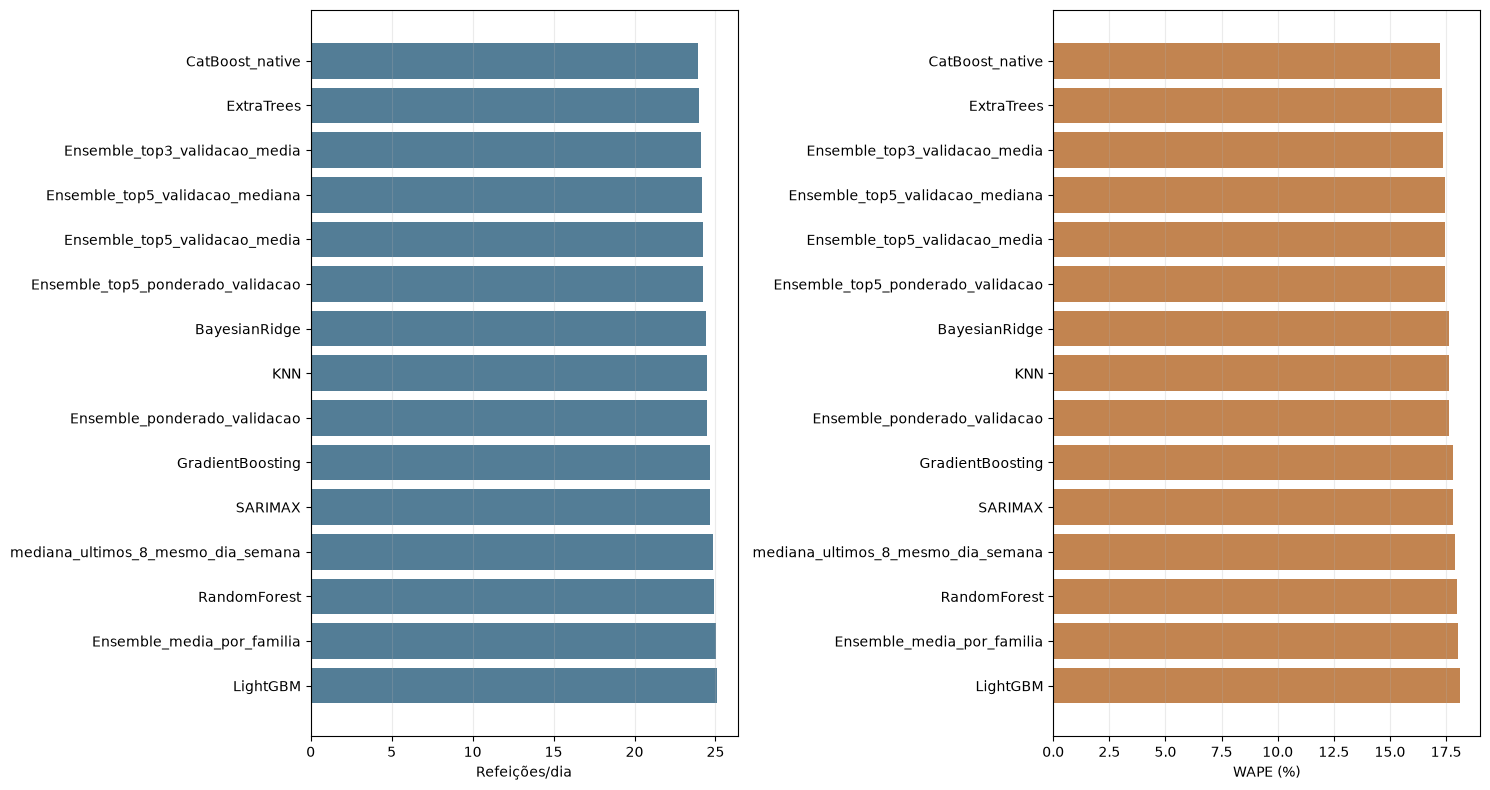

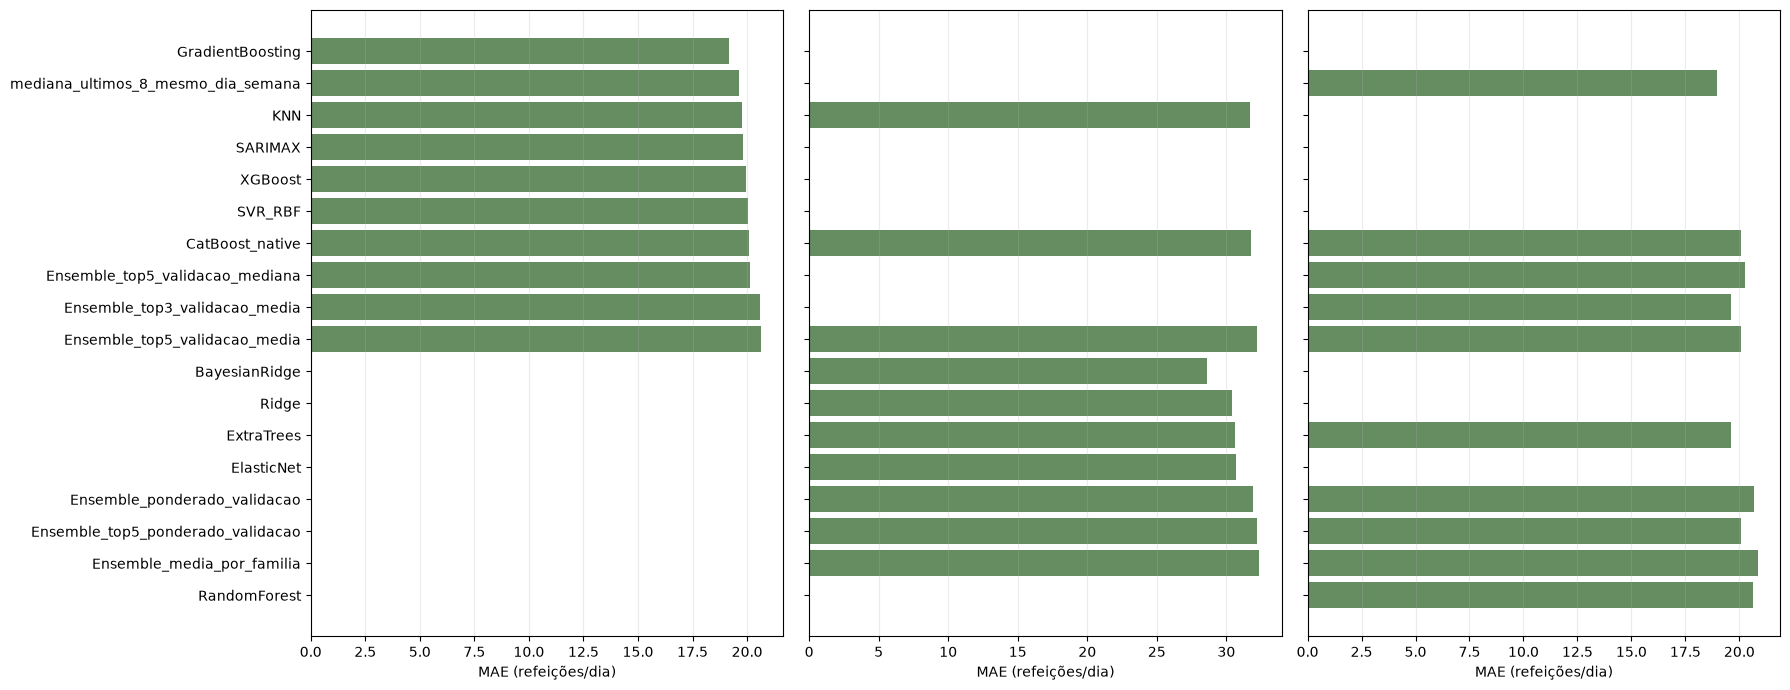

In [5]:
# Vitórias por fold em MAE: contagem descritiva, sem inferência estatística.
fold_winners = (fold_common.sort_values(["fold", "MAE", "WAPE_pct"])
                .groupby("fold", as_index=False).first())
win_counts = fold_winners.groupby(["modelo", "familia"]).size().rename("folds_com_menor_MAE").reset_index()
win_counts = win_counts.sort_values("folds_com_menor_MAE", ascending=False)
display(win_counts.head(15))

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
top_mae = overall_common.nsmallest(15, "MAE").sort_values("MAE")
axes[0].barh(top_mae["modelo"], top_mae["MAE"], color="#537D96")
axes[0].invert_yaxis(); axes[0].set(xlabel="Refeições/dia")
top_wape = overall_common.nsmallest(15, "WAPE_pct").sort_values("WAPE_pct")
axes[1].barh(top_wape["modelo"], top_wape["WAPE_pct"], color="#C28450")
axes[1].invert_yaxis(); axes[1].set(xlabel="WAPE (%)")
for ax in axes: ax.grid(axis="x", alpha=.25)
fig.tight_layout(); fig.savefig(OUT / "ranking_geral_mae_wape.png", dpi=160, bbox_inches="tight"); plt.show()

years = sorted(annual_common["ano"].unique())
fig, axes = plt.subplots(1, len(years), figsize=(6*len(years), 7), sharey=True)
if len(years) == 1: axes = [axes]
for ax, year in zip(axes, years):
    subset = annual_common.loc[annual_common["ano"].eq(year)].nsmallest(10, "MAE").sort_values("MAE")
    ax.barh(subset["modelo"], subset["MAE"], color="#668C62")
    ax.invert_yaxis(); ax.set_xlabel(str(year)+" · MAE (refeições/dia)"); ax.set_xlabel("MAE (refeições/dia)"); ax.grid(axis="x", alpha=.25)
fig.tight_layout(); fig.savefig(OUT / "ranking_anual_mae.png", dpi=160, bbox_inches="tight"); plt.show()

## Pesos e rastreabilidade dos ensembles

Os pesos são calculados exclusivamente com previsões OOF de origens anteriores. No stacking, os coeficientes do Ridge podem ser negativos e não somar 1; são coeficientes do meta-modelo, não percentuais de participação. O intercepto faz parte da fórmula do meta-modelo e está descrito no método. O primeiro fold usa fallback e está identificado na auditoria.

In [6]:
display(ensemble_audit.head(20))
display(ensemble_weights.loc[ensemble_weights["fold"].isin(ensemble_weights["fold"].drop_duplicates().head(3))].head(40))

# Persistência final e tabelas que permitem repetir a análise sem reajustar modelos.
predictions.to_csv(OUT / "previsoes_modelos_ensembles_baselines.csv", index=False, encoding="utf-8-sig")
overall_all.to_csv(OUT / "metricas_por_cobertura_disponivel.csv", index=False, encoding="utf-8-sig")
overall_common.to_csv(OUT / "metricas_pareadas_gerais.csv", index=False, encoding="utf-8-sig")
annual_common.to_csv(OUT / "metricas_pareadas_por_ano.csv", index=False, encoding="utf-8-sig")
fold_common.to_csv(OUT / "metricas_pareadas_por_fold.csv", index=False, encoding="utf-8-sig")
fold_winners.to_csv(OUT / "vencedores_por_fold.csv", index=False, encoding="utf-8-sig")
win_counts.to_csv(OUT / "contagem_vitorias_por_fold.csv", index=False, encoding="utf-8-sig")
failures.to_csv(OUT / "falhas_modelos.csv", index=False, encoding="utf-8-sig")
ensemble_audit.to_csv(OUT / "auditoria_ensembles.csv", index=False, encoding="utf-8-sig")
ensemble_weights.to_csv(OUT / "pesos_ensembles_por_fold.csv", index=False, encoding="utf-8-sig")
print(f"Resultados finais: {OUT}")

,fold,ensemble,metodo,n_datas_oof_previas,modelos_contribuidores,n_modelos_contribuidores
0,14,Ensemble_media_simples_todos,média/votação igualitária de previsões OOF,0,AdaBoost | BayesianRidge | CatBoost_native | D...,20
1,14,Ensemble_media_por_familia,"média das médias por família, famílias com pes...",0,AdaBoost | CatBoost_native | GradientBoosting ...,20
2,14,Ensemble_top3_validacao_media,arranque: candidatos todos; sem OOF anterior,0,AdaBoost | BayesianRidge | CatBoost_native,3
3,14,Ensemble_top5_validacao_media,arranque: candidatos todos; sem OOF anterior,0,AdaBoost | BayesianRidge | CatBoost_native | D...,5
4,14,Ensemble_top5_validacao_mediana,arranque: candidatos todos; sem OOF anterior,0,AdaBoost | BayesianRidge | CatBoost_native | D...,5
5,14,Ensemble_melhor_por_origem_prequential,arranque: candidatos todos; sem OOF anterior,0,AdaBoost,1
6,14,Ensemble_ponderado_validacao,arranque: pesos iguais; sem OOF anterior,0,AdaBoost | BayesianRidge | CatBoost_native | D...,20
7,14,Ensemble_top5_ponderado_validacao,arranque: pesos iguais; sem OOF anterior,0,AdaBoost | BayesianRidge | CatBoost_native | D...,5
8,14,Ensemble_stacking_temporal_ridge,arranque: média igual; histórico OOF insuficiente,0,AdaBoost | BayesianRidge | CatBoost_native | D...,20
9,15,Ensemble_media_simples_todos,média/votação igualitária de previsões OOF,4,AdaBoost | BayesianRidge | CatBoost_native | D...,20


,fold,ensemble,modelo,peso,tipo_peso,n_datas_oof_previas
0,14,Ensemble_media_simples_todos,AdaBoost,0.050000,peso de combinação,0
1,14,Ensemble_media_simples_todos,BayesianRidge,0.050000,peso de combinação,0
2,14,Ensemble_media_simples_todos,CatBoost_native,0.050000,peso de combinação,0
3,14,Ensemble_media_simples_todos,DecisionTree,0.050000,peso de combinação,0
4,14,Ensemble_media_simples_todos,ElasticNet,0.050000,peso de combinação,0
5,14,Ensemble_media_simples_todos,ExtraTrees,0.050000,peso de combinação,0
6,14,Ensemble_media_simples_todos,GradientBoosting,0.050000,peso de combinação,0
7,14,Ensemble_media_simples_todos,HistGradientBoosting,0.050000,peso de combinação,0
8,14,Ensemble_media_simples_todos,Huber,0.050000,peso de combinação,0
9,14,Ensemble_media_simples_todos,KNN,0.050000,peso de combinação,0


Resultados finais: F:\PRODUTO_MESTRADO\resultados\linhas\consumo_cardapio_calendario\04_competicao_modelos_ensembles


## Interpretação e limites

O ranking usa MAE como ordenação principal e WAPE como complemento; também reporta viés, excesso e falta previstos. Compare cobertura e métricas pareadas antes de interpretar diferenças: um método não pode ganhar por ter sido avaliado em datas mais fáceis. MAE semelhante não prova melhora operacional; a avaliação com desperdício/falta reais exige quantidade produzida e refeições servidas.

O campeão deste experimento é apenas o melhor sob este histórico, horizonte, regra de validação e custo simulado. A seleção em produção deve ser refeita com dados novos, mantendo validação temporal e registro de cada previsão. Prophet e SARIMAX são candidatos exploratórios e não substituem os modelos tabulares que aceitam menu e calendário detalhados.